# Circularity rarely speaks — pipeline de análise

Notebook que reproduz as análises do manuscrito *"Circularity rarely speaks: R-strategies in visitor reviews across ten emerging economies"* (Production, Thematic Section / IJCIEOM 2027).

**Etapas**
1. Leitura do corpus `reviews_raw.csv` e filtragem dos textos vazios
2. Léxico de sementes (estratégias R, cadeia local, artesania, sustentabilidade declarada) e filtro de ruído
3. Recuperação dos trechos candidatos e amostragem (censo + amostra de 200 de Artesania; subamostra dupla de 25%)
4. Leitura da planilha codificada e concordância (kappa de Cohen)
5. Indicadores por avaliação e pesos amostrais
6. Meta-análise de efeitos aleatórios por país (DerSimonian–Laird + Hartung–Knapp, intervalos de predição)
7. Tabelas 2 e 3, análises de sensibilidade e Figura 1

**Arquivos necessários:** `data/reviews_raw.csv` (não versionado; ver README) e os códigos em `data/coded_passages_coder1.csv` e `data/coded_passages_coder2.csv`.

**Requisitos:** Python ≥ 3.10, pandas, numpy, scipy, openpyxl, matplotlib.

Semente aleatória fixa (20261119): a amostragem é idêntica à que gerou a planilha de codificação.

In [1]:
# ---- Configuração ----
RAW_CSV   = '../data/reviews_raw.csv'                     # corpus original (não versionado: conteúdo da plataforma)
CODER1    = '../data/coded_passages_coder1.csv'           # códigos do Codificador 1 (sem texto das avaliações)
CODER2    = '../data/coded_passages_coder2.csv'           # códigos do Codificador 2 (subamostra dupla)
SEED      = 20261119
AR_SAMPLE = 200       # tamanho da amostra de avaliações só de Artesania
DUAL_SHARE = 0.25     # fração da subamostra dupla (Codificador 2)
OUT_DIR   = '../results'

In [2]:
import os, re
import numpy as np
import pandas as pd
import openpyxl
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
os.makedirs(OUT_DIR, exist_ok=True)

## 1. Corpus

In [3]:
raw = pd.read_csv(RAW_CSV).reset_index().rename(columns={'index': 'row_id'})
print('Linhas no arquivo:', len(raw))
df = raw[raw.text.notna() & (raw.text.str.strip() != '')].copy()
print('Avaliações com texto:', len(df), '| fornecedores:', df.place_id.nunique(),
      '| países:', df.country.nunique(), '| cidades:', df.city.nunique())
print(df.segment.value_counts().to_dict())
print('Nota média:', round(df.rating.mean(), 2))

Linhas no arquivo: 54687
Avaliações com texto: 51128 | fornecedores: 11509 | países: 10 | cidades: 29
{'creative': 27527, 'mass_market': 23601}
Nota média: 4.58


## 2. Léxico e filtro de ruído

Grupos na ordem de prioridade usada para definir a *categoria principal automática*. As expressões usam fronteira de palavra. O substantivo *artesanato* não é semente (nomeia a categoria do fornecedor).

In [4]:
LEX = [  # (código, categoria, regex)
 ('R8',  'R8 Reciclar', r'\brecicl\w*'),
 ('R7',  'R7 Repropor / upcycling', r'upcycl\w*|segunda vida|\bsucata\w*|reuso adaptativo|\btransformad[oa]s? em\b'),
 ('R5-6','R5-R6 Restaurar / remanufaturar', r'\brestaur(?:ad[oa]s?|ação|ações|ar|ou)\b'),
 ('R4',  'R4 Reparar', r'\bconsert\w*|\brepar(?:o|os|ar|ou|ação|ações|ado|ada)\b'),
 ('R3',  'R3 Reutilizar', r'\breaprovei\w*|\breutiliz\w*|\breuso\b|segunda mão|\bbrechó\w*|\b(?:roupas?|móveis|livros?|peças?|máquinas?|objetos?|itens|produtos?|artigos?)\s+(?:\w+\s+)?usad[oa]s\b|\bantiguidades?\b|\bantiquári\w*|\bvintage\b'),
 ('R0-2','R0-R2 Recusar / repensar / reduzir', r'desperd[ií]\w*|\bresíduos?\b|\blixo\b|lixo zero|zero waste|\bsobras?\b|\bplástico\w*|\bdescartáve\w*|\bcanudos?\b|\bembalage\w*'),
 ('SD',  'Sustentabilidade declarada', r'sustentáve\w*|sustentabilidade|ecológic\w*|meio ambiente|ambientalmente|eco[- ]?friendly|\becoturism\w*'),
 ('CL',  'Cadeia local', r'\b(?:produt\w*|ingredientes?|matérias?[- ]primas?|insumos?|fornecedor\w*|comida|alimentos?)\s+(?:\w+\s+)?(?:loca(?:l|is)|da região|regiona(?:l|is))\b|comércio justo|fair trade|\bcooperativas? (?:de |das |dos )(?:artes|mulher|produtor|agricult|tecel|bordad|oleir|ceramist|costur)\w*|\borgânic\w*'),
 ('AR',  'Artesania', r'feit[oa]s? (?:à|a) mão|\bartesana(?:l|is)\b|\bartes(?:ão|ãos|ã|ãs)\b'),
]
# usos idiomáticos descartados (janela de 60 caracteres em torno do termo)
NOISE = [r'desperd[ií]\w*\s+(?:de\s+|do\s+|o\s+|meu\s+|seu\s+|nosso\s+|total\s+de\s+)?(?:dinheiro|tempo|dia|viagem|energia)',
         r'\bum lixo\b|\blixo de\b|\bé lixo\b|\bpuro lixo\b|\bque lixo\b',
         r'\bsobras?\s+(?:de\s+)?(?:funcionári|tempo)',
         r'precis\w* de (?:alguns |uns |muitos )?reparos|necessita\w* de (?:alguns )?reparos']

## 3. Recuperação dos trechos candidatos

In [5]:
recs = []
for _, r in df.iterrows():
    low = r.text.lower(); hits = []
    for code_, cat, p in LEX:
        ms = [m for m in re.finditer(p, low)
              if not any(re.search(n, low[max(0, m.start()-60):m.end()+60]) for n in NOISE)]
        if ms: hits.append((code_, cat, ms))
    allm = [(c, m) for c, _, p in LEX for m in re.finditer(p, low)]
    if not hits:
        if allm: recs.append(dict(row_id=r.row_id, grupo='ruido'))
        continue
    recs.append(dict(row_id=r.row_id, grupo='candidato', principal=hits[0][1],
                     codes='; '.join(h[0] for h in hits)))
cand = pd.DataFrame(recs)
print(cand.grupo.value_counts().to_dict())
c_ok = cand[cand.grupo == 'candidato']
print(c_ok.principal.value_counts())

{'candidato': 1605, 'ruido': 78}
principal
Artesania                             629
R0-R2 Recusar / repensar / reduzir    332
R4 Reparar                            190
R3 Reutilizar                         136
Cadeia local                          116
Sustentabilidade declarada            107
R5-R6 Restaurar / remanufaturar        59
R8 Reciclar                            18
R7 Repropor / upcycling                18
Name: count, dtype: int64


### Amostragem
Censo de tudo que não é *só* Artesania; amostra aleatória de 200 avaliações cujo único sinal é Artesania, proporcional ao segmento. A célula confere se os IDs reproduzem exatamente o conjunto da planilha codificada.

In [6]:
c_ok = c_ok.merge(df[['row_id', 'segment']], on='row_id')
ar_only = c_ok[c_ok.codes == 'AR']; rest = c_ok[c_ok.codes != 'AR']
ar_s = pd.concat([g.sample(int(round(AR_SAMPLE * len(g) / len(ar_only))), random_state=SEED)
                  for _, g in ar_only.groupby('segment')])
code_set = pd.concat([rest, ar_s])
print('Universo só Artesania:', len(ar_only), '| amostra:', len(ar_s), '| total a codificar:', len(code_set))

c1 = pd.read_csv(CODER1); c2 = pd.read_csv(CODER2)
print('Conjunto reproduz a planilha:', set(code_set.row_id) == set(c1.row_id.astype(int)))

Universo só Artesania: 629 | amostra: 200 | total a codificar: 1176
Conjunto reproduz a planilha: True


## 4. Codificação: precisão do léxico e concordância

In [7]:
def cohen_kappa(a, b):
    a = list(a); b = list(b); n = len(a)
    po = sum(x == y for x, y in zip(a, b)) / n
    cats = set(a) | set(b)
    pe = sum((a.count(c) / n) * (b.count(c) / n) for c in cats)
    return n, po, (po - pe) / (1 - pe)

pair = c2[['ID', 'C2_relevante', 'C2_estrategia']].merge(c1[['ID', 'C1_relevante', 'C1_estrategia']], on='ID').dropna()
for lab, x, y in [('Relevância', 'C1_relevante', 'C2_relevante'), ('Estratégia', 'C1_estrategia', 'C2_estrategia')]:
    n, po, k = cohen_kappa(pair[x], pair[y]); print(f'{lab}: n={n}  po={po:.3f}  kappa={k:.3f}')
print('Precisão do léxico (relevantes / codificados):', f"{(c1.C1_relevante == 'S').mean():.3f}")

Relevância: n=296  po=0.932  kappa=0.862
Estratégia: n=296  po=0.926  kappa=0.902
Precisão do léxico (relevantes / codificados): 0.601


## 5. Indicadores por avaliação e pesos amostrais

In [8]:
R = ['R0-R2 Recusar / repensar / reduzir', 'R3 Reutilizar', 'R4 Reparar', 'R5-R6 Restaurar / remanufaturar',
     'R7 Repropor / upcycling', 'R8 Reciclar', 'R9 Recuperar (energia)']
c1['S'] = c1.C1_relevante.eq('S')
has = lambda cats: c1.S & (c1.C1_estrategia.isin(cats) | c1.C1_estrategia_2.isin(cats))
c1['circ'] = has(R); c1['local'] = has(['Cadeia local', 'Artesania']); c1['sd'] = has(['Sustentabilidade declarada'])
for r_ in R: c1[r_] = has([r_])
c1['row_id'] = c1.row_id.astype(int)

d = df.merge(c1[['row_id', 'circ', 'local', 'sd'] + R], on='row_id', how='left')
for col in ['circ', 'local', 'sd'] + R: d[col] = d[col].fillna(False).astype(bool)
d['coded'] = d.row_id.isin(c1.row_id); d['ar_univ'] = d.row_id.isin(ar_only.row_id)
# peso = inverso da fração amostral de Artesania, por segmento; não amostrados do universo AR = 0
d['w'] = 1.0
for seg in ['creative', 'mass_market']:
    U = (d.ar_univ & (d.segment == seg)).sum(); S = (d.ar_univ & d.coded & (d.segment == seg)).sum()
    d.loc[d.ar_univ & d.coded & (d.segment == seg), 'w'] = U / S
    d.loc[d.ar_univ & ~d.coded & (d.segment == seg), 'w'] = 0
d['five'] = d.rating == 5; d['neg'] = d.rating <= 2; d['creative'] = d.segment == 'creative'
d['circ_noR4'] = d[[r for r in R if r != 'R4 Reparar']].any(axis=1); d['r4'] = d['R4 Reparar']
print('Avaliações com prática circular:', d.circ.sum(), '| fornecedores:', d[d.circ].place_id.nunique())

Avaliações com prática circular: 342 | fornecedores: 262


## 6. Meta-análise de efeitos aleatórios

Cada país é uma réplica. Prevalências em logit (correção de 0,5 em células nulas); associações em log-OR de tabelas 2×2. τ² por DerSimonian–Laird; IC com ajuste Hartung–Knapp (t com k−1 g.l.); intervalo de predição com t de k−2 g.l.

In [9]:
expit = lambda x: 1 / (1 + np.exp(-x))

def re_meta(y, v):
    y = np.asarray(y, float); v = np.asarray(v, float); k = len(y); wi = 1 / v
    mu_f = (wi * y).sum() / wi.sum(); Q = (wi * (y - mu_f) ** 2).sum()
    Cc = wi.sum() - (wi ** 2).sum() / wi.sum(); tau2 = max(0, (Q - (k - 1)) / Cc)
    ws = 1 / (v + tau2); mu = (ws * y).sum() / ws.sum()
    q = (ws * (y - mu) ** 2).sum() / (k - 1); se = np.sqrt(max(q, 1) / ws.sum())
    t = stats.t.ppf(.975, k - 1); I2 = max(0, (Q - (k - 1)) / Q) if Q > 0 else 0
    tp = stats.t.ppf(.975, k - 2) * np.sqrt(tau2 + se ** 2) if k > 2 else np.nan
    return dict(k=k, mu=mu, lo=mu - t * se, hi=mu + t * se, tau2=tau2, I2=I2, Q=Q,
                p=2 * (1 - stats.t.cdf(abs(mu / se), k - 1)), pi_lo=mu - tp, pi_hi=mu + tp)

def prop_meta(data, unit, col, weighted=False):
    rows = []
    for u, g in data.groupby(unit):
        n = len(g); x = (g[col] * g.w).sum() if weighted else g[col].sum()
        xc, nc = (x + .5, n + 1) if x in (0, n) else (x, n)
        rows.append(dict(unit=u, n=n, x=x, p=x / n, y=np.log(xc / (nc - xc)), v=1 / xc + 1 / (nc - xc)))
    t = pd.DataFrame(rows); m = re_meta(t.y, t.v)
    return t, {**m, 'est': expit(m['mu']), 'ci': (expit(m['lo']), expit(m['hi'])), 'pi': (expit(m['pi_lo']), expit(m['pi_hi']))}

def or_meta(data, unit, expo, out):
    rows = []
    for u, g in data.groupby(unit):
        if g[expo].sum() == 0: continue
        a = (g[expo] & g[out]).sum(); b = (g[expo] & ~g[out]).sum(); c = (~g[expo] & g[out]).sum(); dd = (~g[expo] & ~g[out]).sum()
        if min(a, b, c, dd) == 0: a, b, c, dd = a + .5, b + .5, c + .5, dd + .5
        rows.append(dict(unit=u, n_exp=int(g[expo].sum()), y=np.log(a * dd / (b * c)), v=1/a + 1/b + 1/c + 1/dd))
    t = pd.DataFrame(rows); m = re_meta(t.y, t.v)
    return t, {**m, 'est': np.exp(m['mu']), 'ci': (np.exp(m['lo']), np.exp(m['hi'])), 'pi': (np.exp(m['pi_lo']), np.exp(m['pi_hi']))}

fmt = lambda m, pct=False: (f"{100*m['est']:.2f}% ({100*m['ci'][0]:.2f}–{100*m['ci'][1]:.2f})" if pct
                            else f"{m['est']:.2f} ({m['ci'][0]:.2f}–{m['ci'][1]:.2f})") + f"  I²={100*m['I2']:.0f}%  k={m['k']}  p={m['p']:.3f}"

### 6.1 Prevalência (RQ1) e sensibilidade

In [10]:
res = {}
t_country, res['Prevalência circular (país)'] = prop_meta(d, 'country', 'circ')
_, res['Prevalência circular (cidade)'] = prop_meta(d, 'city', 'circ')
_, res['Prevalência circular sem China'] = prop_meta(d[d.country != 'China'], 'country', 'circ')
_, res['Ecossistema local (ponderado)'] = prop_meta(d, 'country', 'local', weighted=True)
_, res['Sustentabilidade declarada'] = prop_meta(d, 'country', 'sd')
for k_, m in res.items(): print(f'{k_:35s}', fmt(m, pct=True))
m = res['Prevalência circular (país)']; print(f"Intervalo de predição: {100*m['pi'][0]:.2f}–{100*m['pi'][1]:.2f}%  Q={m['Q']:.1f}")

# razão local / circular por país
rows = [dict(unit=u, y=np.log(((g.local * g.w).sum() + .5) / (g.circ.sum() + .5)),
             v=1 / ((g.local * g.w).sum() + .5) + 1 / (g.circ.sum() + .5)) for u, g in d.groupby('country')]
mr = re_meta(pd.DataFrame(rows).y, pd.DataFrame(rows).v)
print(f"Razão local/circular: {np.exp(mr['mu']):.2f} ({np.exp(mr['lo']):.2f}–{np.exp(mr['hi']):.2f})  p={mr['p']:.3f}")

Prevalência circular (país)         0.73% (0.45–1.18)  I²=93%  k=10  p=0.000
Prevalência circular (cidade)       0.69% (0.52–0.93)  I²=83%  k=29  p=0.000
Prevalência circular sem China      0.68% (0.40–1.15)  I²=94%  k=9  p=0.000
Ecossistema local (ponderado)       1.20% (0.82–1.76)  I²=94%  k=10  p=0.000
Sustentabilidade declarada          0.17% (0.09–0.31)  I²=66%  k=10  p=0.000
Intervalo de predição: 0.15–3.41%  Q=131.9
Razão local/circular: 1.62 (0.80–3.31)  p=0.158


### 6.2 Segmento (RQ2) e notas (RQ3) — Tabela 3

In [11]:
_, m = or_meta(d, 'country', 'creative', 'circ'); print('OR circular, criativo vs massa:', fmt(m))
specs = [('Any circular report (R0–R8)', 'circ', 'five'), ('Any circular report (R0–R8)', 'circ', 'neg'),
         ('Circular report excluding repair', 'circ_noR4', 'five'), ('Circular report excluding repair', 'circ_noR4', 'neg'),
         ('Repair (R4)', 'r4', 'five'), ('Repair (R4)', 'r4', 'neg'),
         ('Generic sustainability claim', 'sd', 'five'), ('Generic sustainability claim', 'sd', 'neg'),
         ('Local or artisanal report', 'local', 'five')]
tab3 = []
for lab, e, o in specs:
    data = d[d.w > 0] if e == 'local' else d      # local: só avaliações observáveis (exclui AR não amostrado)
    _, m = or_meta(data, 'country', e, o)
    tab3.append({'Exposure': lab, 'Outcome': '5 stars' if o == 'five' else '1–2 stars', 'k': m['k'],
                 'OR': round(m['est'], 2), '95% CI': f"{m['ci'][0]:.2f}–{m['ci'][1]:.2f}", 'I² (%)': round(100 * m['I2']), 'p': round(m['p'], 3)})
tab3 = pd.DataFrame(tab3); tab3

OR circular, criativo vs massa: 4.23 (2.51–7.14)  I²=54%  k=10  p=0.000


,Exposure,Outcome,k,OR,95% CI,I² (%),p
0,Any circular report (R0–R8),5 stars,10,0.58,0.43–0.78,4,0.002
1,Any circular report (R0–R8),1–2 stars,10,1.65,1.14–2.38,0,0.013
2,Circular report excluding repair,5 stars,10,0.62,0.42–0.93,11,0.024
3,Circular report excluding repair,1–2 stars,10,1.07,0.52–2.22,28,0.829
4,Repair (R4),5 stars,9,0.48,0.30–0.77,6,0.007
5,Repair (R4),1–2 stars,9,3.20,1.94–5.27,0,0.001
6,Generic sustainability claim,5 stars,9,1.00,0.47–2.15,0,0.991
7,Generic sustainability claim,1–2 stars,9,1.83,0.82–4.09,0,0.122
8,Local or artisanal report,5 stars,10,1.53,0.99–2.35,0,0.054


## 7. Tabela 2 e distribuição por país

In [12]:
c1s = c1[c1.S]
g = c1s.groupby('C1_estrategia')
pct = lambda cond: g.apply(lambda x: round(100 * cond(x).mean()))
tab2 = pd.DataFrame({'Passages': g.size(),
    'Creative (%)': pct(lambda x: x.Segmento == 'creative'),
    'Supplier (%)': pct(lambda x: x.C1_quem == 'Fornecedor'),
    'Visitor (%)': pct(lambda x: x.C1_quem == 'Visitante'),
    'Destination (%)': pct(lambda x: x.C1_quem == 'Destino / comunidade'),
    'Positive (%)': pct(lambda x: x.C1_valencia == 'Positiva'),
    'Negative (%)': pct(lambda x: x.C1_valencia == 'Negativa'),
    'Mean rating': g.Nota.mean().round(2)})
display(tab2)
display(pd.crosstab(c1s[c1s.C1_estrategia.isin(R)]['País'], c1s[c1s.C1_estrategia.isin(R)].C1_estrategia))

,Passages,Creative (%),Supplier (%),Visitor (%),Destination (%),Positive (%),Negative (%),Mean rating
C1_estrategia,,,,,,,,
Artesania,222,97,87,6,7,86,4,4.79
Cadeia local,78,79,81,12,8,77,0,4.82
R0-R2 Recusar / repensar / reduzir,22,91,45,55,0,50,32,4.09
R3 Reutilizar,98,95,84,3,13,52,3,4.64
R4 Reparar,132,85,91,5,4,64,19,4.08
R5-R6 Restaurar / remanufaturar,52,56,58,2,40,42,8,4.25
R7 Repropor / upcycling,15,67,80,7,13,73,7,4.27
R8 Reciclar,12,58,50,8,42,67,8,4.75
Sustentabilidade declarada,76,66,93,5,1,71,8,4.66


C1_estrategia,R0-R2 Recusar / repensar / reduzir,R3 Reutilizar,R4 Reparar,R5-R6 Restaurar / remanufaturar,R7 Repropor / upcycling,R8 Reciclar
País,,,,,,
Brazil,3,12,7,13,4,2
China,0,5,0,10,0,0
Egypt,5,16,13,0,0,1
Ethiopia,0,1,1,0,2,0
India,7,2,12,4,4,5
Iran,1,5,4,5,0,1
Russia,2,1,37,13,1,0
Saudi Arabia,0,41,23,4,0,0
South Africa,2,1,8,1,4,2


## 8. Figura 1 — forest plot

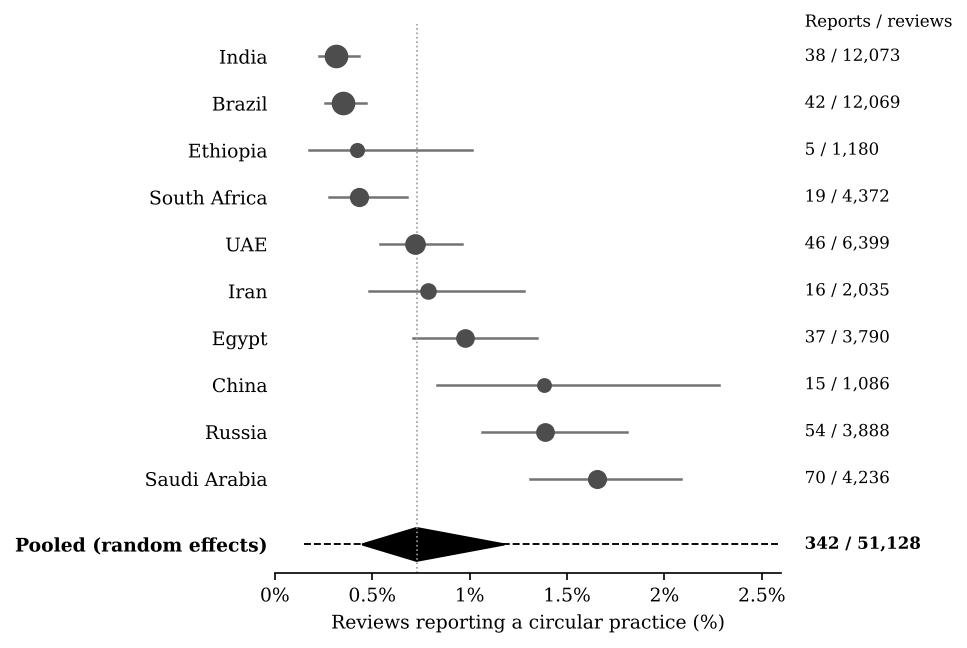

In [13]:
t = t_country.copy()
t['lo'] = expit(t.y - 1.96 * np.sqrt(t.v)); t['hi'] = expit(t.y + 1.96 * np.sqrt(t.v))
t = t.sort_values('p'); t['unit'] = t.unit.replace({'United Arab Emirates': 'UAE'})
m = res['Prevalência circular (país)']
plt.rcParams['font.family'] = 'DejaVu Serif'; plt.rcParams['font.size'] = 9
fig, ax = plt.subplots(figsize=(6.6, 4.4), dpi=150); n = len(t)
for i, r in enumerate(t.itertuples()):
    y = n - i
    ax.plot([100 * r.lo, 100 * r.hi], [y, y], color='0.45', lw=1.2)
    ax.scatter([100 * r.p], [y], s=8 + np.sqrt(r.n) * 0.9, color='0.3', zorder=3)
    ax.text(2.72, y, f'{int(r.x)} / {r.n:,}', va='center', fontsize=8)
y0 = -0.4; est, lo, hi = 100 * m['est'], 100 * m['ci'][0], 100 * m['ci'][1]
ax.plot([100 * m['pi'][0], min(100 * m['pi'][1], 2.6)], [y0, y0], ls='--', color='black', lw=0.9)
ax.fill([lo, est, hi, est], [y0, y0 + .35, y0, y0 - .35], color='black')
ax.text(2.72, y0, f'{int(t.x.sum())} / {t.n.sum():,}', va='center', fontsize=8, fontweight='bold')
ax.axvline(est, color='0.6', ls=':', lw=0.8)
ax.set_yticks(list(range(n, 0, -1)) + [y0]); ax.set_yticklabels(list(t.unit) + ['Pooled (random effects)'])
ax.get_yticklabels()[-1].set_fontweight('bold')
ax.set_xlim(0, 2.6); ax.set_ylim(-1.0, n + 0.7)
ax.set_xticks([0, .5, 1, 1.5, 2, 2.5]); ax.set_xticklabels(['0%', '0.5%', '1%', '1.5%', '2%', '2.5%'])
ax.set_xlabel('Reviews reporting a circular practice (%)'); ax.text(2.72, n + .55, 'Reports / reviews', fontsize=8, va='bottom')
for s in ['top', 'right', 'left']: ax.spines[s].set_visible(False)
ax.tick_params(axis='y', length=0); plt.tight_layout()
plt.savefig(f'{OUT_DIR}/Figure1.png', dpi=300, bbox_inches='tight'); plt.show()

## 9. Exportação dos resultados

In [14]:
summary = pd.DataFrame([{'Estimate': k_, 'Pooled': round(100 * m['est'], 3), 'CI low': round(100 * m['ci'][0], 3),
                         'CI high': round(100 * m['ci'][1], 3), 'I2 (%)': round(100 * m['I2']), 'k': m['k']} for k_, m in res.items()])
with pd.ExcelWriter(f'{OUT_DIR}/resultados_meta_analise.xlsx') as xw:
    summary.to_excel(xw, sheet_name='Prevalencias', index=False)
    tab3.to_excel(xw, sheet_name='Tabela3_OR', index=False)
    tab2.to_excel(xw, sheet_name='Tabela2_estrategias')
    t_country.to_excel(xw, sheet_name='Paises', index=False)
print('Arquivos salvos em', OUT_DIR)

Arquivos salvos em ../results
